In [1]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '7'

import deepxde as dde 
dde.config.disable_xla_jit()
from deepxde.backend import tf
from functools import reduce
import argparse

parser = argparse.ArgumentParser(description='Set parameters')


Using backend: tensorflow

2022-11-08 23:32:59.967733: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-08 23:33:01.215941: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2022-11-08 23:33:01.288687: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:e1:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-08 23:33:01.288708: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-08 23:33:01.291071: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-08 23:33:01.291102: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dyn

Enable just-in-time compilation with XLA.

Disable just-in-time compilation with XLA.



no uniform points
Compiling model...
'compile' took 0.000884 s



2022-11-08 23:33:02.319220: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-11-08 23:33:02.327866: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:e1:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-08 23:33:02.333595: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1871] Adding visible gpu devices: 0
2022-11-08 23:33:02.333681: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-08 23:33:02.794774: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1258] Device interconnect StreamExecu

Training model...



2022-11-08 23:33:07.925807: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:176] None of the MLIR Optimization Passes are enabled (registered 2)
2022-11-08 23:33:07.970267: I tensorflow/core/platform/profile_utils/cpu_utils.cc:114] CPU Frequency: 3000030000 Hz
2022-11-08 23:33:08.632231: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-08 23:33:09.010167: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11


Step      Train loss    Test loss     Test metric
0         [2.41e+05]    [2.26e+05]    []  
1000      [5.22e+04]    [6.65e+04]    []  
2000      [3.40e+04]    [7.09e+04]    []  
3000      [2.47e+04]    [7.19e+04]    []  
4000      [1.75e+04]    [6.54e+04]    []  
5000      [1.20e+04]    [5.91e+04]    []  
6000      [8.24e+03]    [5.00e+04]    []  
7000      [5.87e+03]    [4.14e+04]    []  
8000      [4.59e+03]    [3.42e+04]    []  
9000      [3.83e+03]    [2.87e+04]    []  
10000     [4.61e+03]    [2.49e+04]    []  
11000     [2.13e+03]    [2.02e+04]    []  
12000     [3.88e+03]    [1.96e+04]    []  
13000     [1.47e+04]    [1.88e+04]    []  
14000     [3.50e+03]    [8.88e+03]    []  
15000     [2.41e+03]    [8.10e+03]    []  

Best model at step 11000:
  train loss: 2.13e+03
  test loss: 2.02e+04
  test metric: []

'train' took 868.830577 s

Saving loss history to /root/shared/UQ/Tensor-PINNs/Helmholtz/loss.dat ...
Saving training data to /root/shared/UQ/Tensor-PINNs/Helmholtz/train.

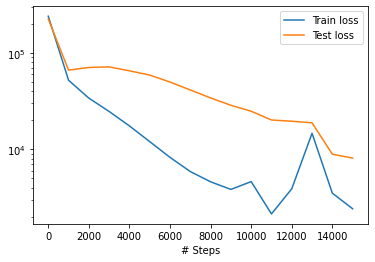

In [2]:
#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
N_f = 5000
N_f_test = 5000

epochs = 15000 
parameters = [1e-2, 2, 250, "sin"] 
#parameters = [1e-2, 2, 500, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    dy1_xx = dde.grad.hessian(y, x, i=0, j=0)
    dy1_yy = dde.grad.hessian(y, x, i=1, j=1)

    dy1_zz = dde.grad.hessian(y, x, i=2, j=2)
    dy1_tt = dde.grad.hessian(y, x, i=3, j=3)

    D1 = dy1_xx + dy1_yy
    D2 = dy1_zz + dy1_tt
    
    D1D2 = dde.grad.hessian(D2, x, i=0, j=0) + dde.grad.hessian(D2, x, i=1, j=1)
    
    A = D1D2 + k0 ** 2* D1 + k0 ** 2 * D2 + k0 ** 4 * y    
        
    dist = tf.abs(x[:, 0:1] - x[:, 2:3])
    F =  k0 ** 4 * tf.exp(- dist * 10)
    
    res = A - F
    return res

def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])
    return res1 * res2 * y


def boundary(_, on_boundary):
    return on_boundary

geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [4] + [num_dense_nodes] * num_dense_layers + [1], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate)
losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

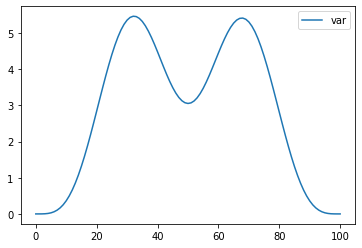

In [3]:
k = 2
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
pred = model.predict(xx)
fig = plt.figure()
plt.plot(pred.ravel(), label=r'var')
plt.legend()

In [14]:
u_sca.min(), u_sca.max()
# (0.0, 8.384518)

(0.0, 8.384518)

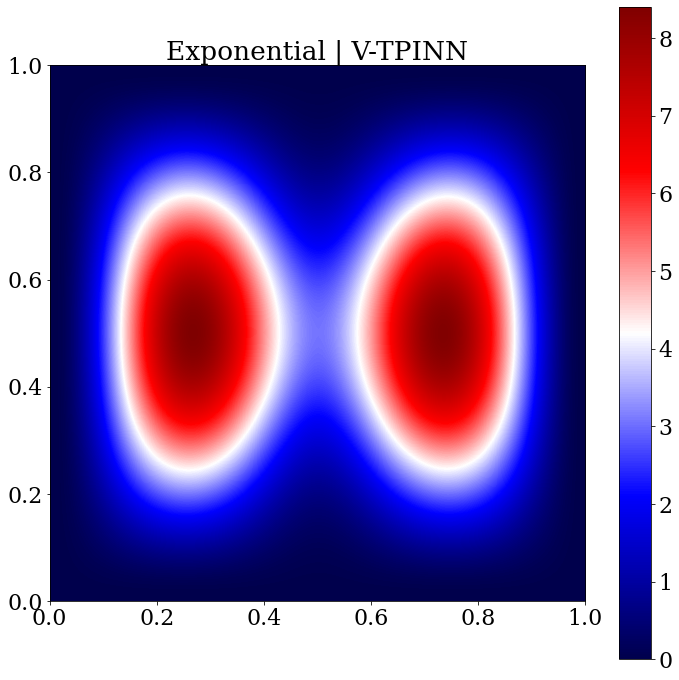

In [16]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

vmin = 0
vmax = 8.4

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='V-TPINNs', vmin=vmin, vmax=vmax)

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('Exponential | V-TPINN')
plt.savefig('Exponential.pdf')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Text(0.5, 1.0, 'Exponential')

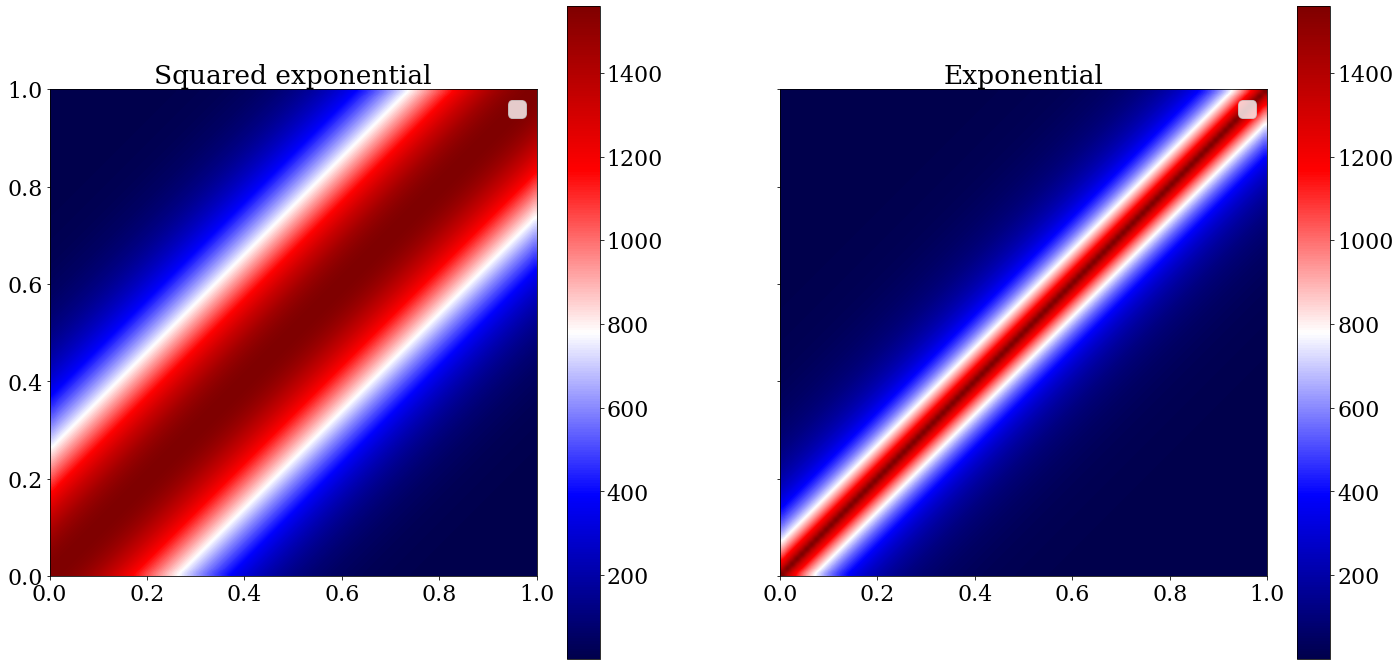

In [7]:

    from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

x = points.T

dist = np.abs(x[:, 0:1] - x[:, 1:2]) ** 2
F1 = k0 ** 4 * np.exp(- dist * 10)

F1 = F1.reshape((Nx, Ny))    


dist = np.abs(x[:, 0:1] - x[:, 1:2])
F2 =  k0 ** 4 * np.exp(- dist * 10)

F2 = F2.reshape((Nx, Ny))    

F3 =  k0 ** 4 * np.exp(- dist * 10)



'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)

fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize = (24,12))

pcm = ax1.imshow(np.fliplr(F1).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')


pcm = ax2.imshow(np.fliplr(F2).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
fig.colorbar(pcm, ax = ax2)
ax1.legend()
ax2.legend()
ax1.set_title('Squared exponential')
ax2.set_title('Exponential')
